# transistor：更新回数を揃えた通常学習と回転拡張のAUROC比較

**通常学習だけを新規に学習し、回転拡張は保存済みモデルを再利用します。** 今回の比較モデルはHybrid CNN＋FCです。今後の基本モデルCNN Deep5とは別の検証です。

- 両条件とも6,700更新。通常画像213枚・バッチ32では、957周（6,699更新）＋次の1バッチです。
- βは回転拡張の保存ログを更新単位に展開して使用します。通常学習のエポック数に対して増加させません。
- 回転拡張モデル：実行 `20261106_002435_9b4da165`、seed42、100エポック。再学習・上書きしません。
- 正式学習の初期設定は `RUN_FULL_TRAINING = True`。実行はユーザーが行います。
- 再評価だけの場合：設定を `RUN_FULL_TRAINING = False` にし、`NORMAL_RUN_ID` に保存済み実行IDを指定（Noneは最新の完了実行）して上から実行します。

## この比較で揃うこと・残る違い
モデル構造、初期重み、最適化手法、更新回数、更新に対するβ、評価データと推論方法を揃えます。一方、通常は32枚×6＋21枚、回転拡張は32枚×66＋18枚で1周です。小バッチの頻度、総提示枚数、入力分布、画像順、BatchNormの統計、乱数の対応は同一ではありません。したがって回転だけの効果を完全に分離した実験とは表現しません。

補完方法などの詳細は設定へ記録し、発表向けの表示名は「通常学習」「回転拡張」に統一します。性能指標はAUROCのみ。共通正常画像の復元誤差は補助情報です。


In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
from pathlib import Path
from io import BytesIO
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import importlib.metadata
import json
import math
import platform
import random
import time
import uuid
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from skimage.metrics import structural_similarity as ssim

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'memory/memory.md').is_file() and (p/'data/transistor').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('リポジトリ内を作業ディレクトリにしてください。')
SOURCE_RUN = ROOT/'saved_models/transistor_rotation_control_20261106_reflect/20261106_002435_9b4da165'
SOURCE_MODEL = SOURCE_RUN/'seed_42/B_rotate10/model_final.pth'
EXPECTED_MODEL_SHA256 = '20b0568e0cbae99290cb474b7e327a95983368fb37ece7edbcd0cd1c91f42de5'
OUTPUT_BASE = ROOT/'saved_models/transistor_update_matched_20261106'
EXPERIMENT = 'transistor_update_matched_20261106_v1'
RUN_FULL_TRAINING = True
NORMAL_RUN_ID = None
assert not (RUN_FULL_TRAINING and NORMAL_RUN_ID is not None), '保存済み通常モデルを使う場合はRUN_FULL_TRAINING=Falseにしてください。'
MAX_IMAGES_PER_CATEGORY = 1  # Noneですべてのテスト画像を表示
SEED = 42
LATENT_DIM = 64
BATCH_SIZE = 32
LEARNING_RATE = 0.001
TOP_K = 130
EVAL_BATCH_SIZE = 32
DEVICE = torch.device('cpu')  # 保存済み実験と同じCPU。変更時は環境差が残ります。
CONDITIONS = ('A_original', 'B_rotate10')
LABELS = {'A_original':'A：通常学習', 'B_rotate10':'B：回転拡張'}
COLORS = {'A_original':'#526b8e', 'B_rotate10':'darkorange'}
TEST_DIR = ROOT/'data/transistor/test'
category_labels = {'good':'正常','bent_lead':'端子の曲がり','cut_lead':'端子の切断',
                   'damaged_case':'本体の損傷','misplaced':'配置ずれ'}
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ['Yu Gothic','Meiryo','MS Gothic','Noto Sans CJK JP','IPAexGothic']:
    if font in available_fonts:
        plt.rcParams['font.family'] = font
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size':11,'axes.unicode_minus':False,'figure.dpi':100})
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
def write_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2)+chr(10), encoding='utf-8')
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
def new_id():
    return datetime.now(ZoneInfo('Asia/Tokyo')).strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:8]
print('正式学習：', RUN_FULL_TRAINING, '/ デバイス：', DEVICE)


正式学習： True / デバイス： cpu


## 1. 回転拡張の保存設定・重み・βを確認（読み込み専用）


In [2]:
source_config = read_json(SOURCE_RUN/'config.json')
source_summary = read_json(SOURCE_MODEL.parent/'summary.json')
source_history = pd.read_csv(SOURCE_MODEL.parent/'history.csv')
assert source_config['status'] == 'completed'
assert source_config['dataset'] == 'transistor'
assert source_config['conditions'] == list(CONDITIONS)
assert source_config['design_version'] == 4
assert source_config['batch_size'] == BATCH_SIZE and source_config['latent_dim'] == LATENT_DIM
assert source_config['learning_rate'] == LEARNING_RATE and source_config['optimizer'] == 'Adam'
assert source_config['source_size'] == [1024,1024] and source_config['network_input_size'] == [128,128]
assert source_config['epochs'] == 100 and source_config['annealing_epochs'] == 50
assert source_config['beta_rule'] == 'min(1.0, zero_based_epoch / annealing_epochs)'
assert source_config['seeds'] == [SEED] and source_config['train_normal_count'] == 213
assert source_config['rotation_background'] == 'reflect'
assert source_config['angles'] == list(range(0,360,36))
assert source_config['rotation_stage'] == 'full_resolution_before_resize'
assert source_summary['condition'] == 'B_rotate10' and source_summary['seed'] == SEED
assert source_summary['updates'] == 6700 and source_summary['images_per_epoch'] == 2130
assert sha256(SOURCE_MODEL) == EXPECTED_MODEL_SHA256, '回転拡張モデルが想定と異なります。'
assert np.array_equal(source_history.epoch, np.arange(1,101))
assert np.array_equal(source_history.updates, np.full(100,67))
assert np.array_equal(source_history.cumulative_updates, np.arange(1,101)*67)
assert np.allclose(source_history.beta, np.minimum(np.arange(100)/50,1), rtol=0, atol=1e-12)
TARGET_UPDATES = int(source_summary['updates'])
beta_by_update = np.repeat(source_history.beta.to_numpy(float), source_history.updates.to_numpy(int))
assert len(beta_by_update) == TARGET_UPDATES
beta_sha256 = hashlib.sha256(beta_by_update.astype('<f8').tobytes()).hexdigest()
# 読み込み対象の設定・ログも実行中に変わらないことを終了時に確認します。
source_files = [SOURCE_MODEL, SOURCE_RUN/'config.json', SOURCE_MODEL.parent/'summary.json',
                SOURCE_MODEL.parent/'history.csv', SOURCE_RUN/'train_manifest.json', SOURCE_RUN/'test_manifest.json']
source_file_hashes = {p.relative_to(ROOT).as_posix():sha256(p) for p in source_files}
print(f'回転拡張：{source_summary["epochs"]}エポック / {TARGET_UPDATES:,}更新')
print('回転拡張を再学習する処理は、このノートブックにはありません。')


回転拡張：100エポック / 6,700更新
回転拡張を再学習する処理は、このノートブックにはありません。


## 2. 共通の前処理と画像の照合

画像全体1024×1024 → LANCZOSで128×128 → 白黒 → 0〜1。通常学習・評価では回転や補完を行いません。


In [3]:
final_transform = transforms.Compose([
    transforms.Resize((128,128), interpolation=transforms.InterpolationMode.LANCZOS),
    transforms.Grayscale(num_output_channels=1),
])
to_tensor = transforms.ToTensor()
saved_train_manifest = read_json(SOURCE_RUN/'train_manifest.json')
train_paths = sorted((ROOT/'data/transistor/train/good').glob('*.png'), key=lambda p:p.name)
assert [p.relative_to(ROOT).as_posix() for p in train_paths] == [r['path'] for r in saved_train_manifest]
assert len(train_paths) == 213
train_tensors, train_manifest = [], []
for path, record in zip(train_paths, saved_train_manifest):
    raw = path.read_bytes()
    assert hashlib.sha256(raw).hexdigest() == record['file_sha256']
    with Image.open(BytesIO(raw)) as im:
        assert im.size == (1024,1024)
        tensor = to_tensor(final_transform(im.convert('RGB')))
    assert hashlib.sha256(tensor.numpy().tobytes()).hexdigest() == record['preprocessed_sha256']
    train_tensors.append(tensor)
    train_manifest.append(record)
train_tensor = torch.stack(train_tensors)
assert tuple(train_tensor.shape) == (213,1,128,128)
assert torch.isfinite(train_tensor).all() and 0 <= train_tensor.min() <= train_tensor.max() <= 1
PREPARE_TRAINING_DATA = True  # 下の評価データ照合セル用。拡張画像は作りません。
normal_updates_per_epoch = math.ceil(len(train_tensor)/BATCH_SIZE)
full_epochs, last_batches = divmod(TARGET_UPDATES, normal_updates_per_epoch)
assert (full_epochs,last_batches) == (957,1)
display(pd.DataFrame([
    {'条件':LABELS['A_original'],'画像数/周':213,'更新数/周':7,'学習量':'957周＋1バッチ','総更新数':TARGET_UPDATES},
    {'条件':LABELS['B_rotate10'],'画像数/周':2130,'更新数/周':67,'学習量':'保存済み100周','総更新数':TARGET_UPDATES},
]))


,条件,画像数/周,更新数/周,学習量,総更新数
0,A：通常学習,213,7,957周＋1バッチ,6700
1,B：回転拡張,2130,67,保存済み100周,6700


In [4]:
paths = sorted(TEST_DIR.glob('*/*.png'), key=lambda p: p.relative_to(TEST_DIR).as_posix())
counts = {name: sum(p.parent.name == name for p in paths) for name in category_labels}
if counts != {'good':60,'bent_lead':10,'cut_lead':10,'damaged_case':10,'misplaced':10}:
    raise ValueError(f'計画時の評価データ100枚と異なります: {counts}')

inputs, image_records = [], []
for path in paths:
    raw = path.read_bytes()
    with Image.open(BytesIO(raw)) as im:
        tensor = to_tensor(final_transform(im.convert('RGB')))
    inputs.append(tensor)
    image_records.append({
        'relative_path': path.relative_to(TEST_DIR).as_posix(),
        'repo_path': path.relative_to(ROOT).as_posix(),
        'category': path.parent.name,
        'category_ja': category_labels[path.parent.name],
        'true_label': int(path.parent.name != 'good'),
        'file_sha256': hashlib.sha256(raw).hexdigest(),
        'preprocessed_sha256': hashlib.sha256(tensor.numpy().tobytes()).hexdigest(),
    })
input_tensor = torch.stack(inputs)
image_table = pd.DataFrame(image_records)
assert tuple(input_tensor.shape) == (100,1,128,128)

manifest_hash = hashlib.sha256(json.dumps(image_records, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()
display(pd.DataFrame([{'種類': category_labels[name], '枚数': count} for name,count in counts.items()]))
print(f'評価データ識別値：{manifest_hash}')
if PREPARE_TRAINING_DATA:
    assert not {r['file_sha256'] for r in train_manifest} & {r['file_sha256'] for r in image_records}
    assert not {r['preprocessed_sha256'] for r in train_manifest} & {r['preprocessed_sha256'] for r in image_records}


,種類,枚数
0,正常,60
1,端子の曲がり,10
2,端子の切断,10
3,本体の損傷,10
4,配置ずれ,10


評価データ識別値：d7d8a95c32050c0e968424b9d628a4da8b25e68f9db30f2daaa40790ca46db82


In [5]:
assert image_records == read_json(SOURCE_RUN/'test_manifest.json'), '評価画像または前処理が以前と異なります。'
assert manifest_hash == source_config['test_manifest_sha256']


## 3. 保存済みモデルと同じHybrid CNN＋FC

クラス・初期化・損失定義は既存ノートブックと同じです。初期状態のハッシュを保存済み回転拡張の記録と照合します。


In [6]:
class VAE_Hybrid_CNN_FC(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE_Hybrid_CNN_FC, self).__init__()

        # -------------------------------------------------------------
        # 【エンコーダ前半】 CNN_Deep5（空間圧縮: 128x128 -> 4x4）
        # -------------------------------------------------------------
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【エンコーダ後半】 FC_Only（段階的圧縮: 4096次元 -> 128次元）
        # -------------------------------------------------------------
        self.encoder_fc = nn.Sequential(
            nn.Linear(256 * 4 * 4, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )

        # 潜在空間へのマッピング（128次元 -> 64次元）
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # -------------------------------------------------------------
        # 【デコーダ前半】 FC_Only（段階的復元: 64次元 -> 4096次元）
        # -------------------------------------------------------------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            # ※CNNへ繋ぐため、最後はSigmoidではなくReLUを使用します
            nn.Linear(1024, 256 * 4 * 4), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【デコーダ後半】 CNN_Deep5（空間復元: 4x4 -> 128x128）
        # -------------------------------------------------------------
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x, sample=True):
        # 1. CNNによる特徴抽出
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        # 2. FCによる段階的圧縮
        h = self.encoder_fc(h)

        # 3. 潜在変数の計算と安全装置（クランプ）
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if sample else mu

        # 4. FCによる段階的復元
        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 256, 4, 4) # 4階テンソルに戻す

        # 5. CNNによる画像復元
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar

def vae_loss(recon_x, x, mu, logvar, beta=1.0):  
    MSE = nn.functional.mse_loss(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE, KLD, MSE + beta * KLD

def seed_everything(seed):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))

def copy_cpu_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def state_digest(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode('utf-8') + str(tensor.dtype).encode('ascii'))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def make_initial_state(seed):
    seed_everything(seed)
    initial_model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM)
    return copy_cpu_state(initial_model)

def new_model(initial_state, seed, device=DEVICE):
    model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM).to(device)
    model.load_state_dict(initial_state, strict=True)
    # モデル構築で消費された乱数を戻し、各条件のサンプリング列を揃える。
    seed_everything(seed)
    return model


## 4. 更新単位でβを合わせ、通常学習だけを6,700更新

損失は画素の二乗誤差の合計＋β×通常VAEのKLです。各更新のβは回転拡張ログと一致させます。

学習ログは回転拡張の1エポックに対応する**67更新ずつ**集計します。これは通常画像の1エポックではありません。最後のログ値も通常画像1周の誤差ではなく、最後の67更新の画像あたり平均です。バッチサイズも記録します。

中断時には状態を未完了と記録します。途中からの学習再開は実装せず、再実行は別の実行フォルダで最初から行います。完了したモデルは再学習せず読み込めます。


In [7]:
def training_settings():
    return {'experiment':EXPERIMENT, 'version':1, 'model':'Hybrid CNN + FC',
            'seed':SEED, 'batch_size':BATCH_SIZE, 'learning_rate':LEARNING_RATE,
            'latent_dim':LATENT_DIM, 'target_updates':TARGET_UPDATES,
            'beta_schedule_sha256':beta_sha256, 'source_run':SOURCE_RUN.relative_to(ROOT).as_posix(),
            'source_model_sha256':EXPECTED_MODEL_SHA256,
            'source_initial_state_sha256':source_summary['initial_state_sha256'],
            'test_manifest_sha256':manifest_hash, 'device':str(DEVICE)}

def train_normal_only():
    initial = make_initial_state(SEED)
    initial_hash = state_digest(initial)
    assert initial_hash == source_summary['initial_state_sha256'], '初期重みが一致しません。環境やモデル定義を確認してください。'
    directory = OUTPUT_BASE/new_id()
    directory.mkdir(parents=True, exist_ok=False)
    config = {**training_settings(), 'status':'running', 'run_id':directory.name,
              'optimizer':'Adam', 'training_loss':'sum pixel SSE + beta * sum standard-normal KL',
              'training_inference':'posterior sampling', 'evaluation_inference':'posterior mean',
              'normal_full_epochs':full_epochs, 'normal_extra_batches':last_batches,
              'source_rotation_config':source_config, 'source_file_hashes':source_file_hashes,
              'preprocessing':source_config['test_preprocessing'],
              'initial_state_sha256':initial_hash, 'python':platform.python_version(),
              'versions':{v:importlib.metadata.version(v) for v in ['torch','torchvision','numpy','Pillow']},
              'torch_threads':torch.get_num_threads(),
              'note':'Updates and beta matched; input distribution, batch sizes and sample order differ.'}
    write_json(directory/'config.json', config)
    write_json(directory/'train_manifest.json', train_manifest)
    write_json(directory/'test_manifest.json', image_records)
    pd.DataFrame({'update':np.arange(1,TARGET_UPDATES+1),'beta':beta_by_update}).to_csv(directory/'beta_schedule.csv',index=False)
    model = new_model(initial, SEED)
    assert state_digest(copy_cpu_state(model)) == initial_hash
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    generator = torch.Generator().manual_seed(SEED+1000)
    loader = DataLoader(TensorDataset(train_tensor, torch.arange(len(train_tensor))),
                        batch_size=BATCH_SIZE, shuffle=True, generator=generator,
                        drop_last=False, num_workers=0)
    updates = 0
    step_rows, window_rows = [], []
    order_digest = hashlib.sha256()
    window_sums = np.zeros(3,dtype=float)
    window_seen = 0
    started = time.perf_counter()
    try:
        epoch = 0
        while updates < TARGET_UPDATES:
            epoch += 1
            for batch_in_epoch,(images,parents) in enumerate(loader, start=1):
                images = images.to(DEVICE)
                model.train()
                beta = float(beta_by_update[updates])
                optimizer.zero_grad(set_to_none=True)
                reconstruction,mu,logvar = model(images,sample=True)
                sse_value,kl_value,total_value = vae_loss(reconstruction,images,mu,logvar,beta)
                if not all(torch.isfinite(v).item() for v in [sse_value,kl_value,total_value]):
                    raise FloatingPointError('損失にNaN/infがあります。')
                total_value.backward()
                if any(p.grad is not None and not torch.isfinite(p.grad).all().item() for p in model.parameters()):
                    raise FloatingPointError('勾配にNaN/infがあります。')
                optimizer.step()
                order_digest.update(parents.numpy().astype('<i8').tobytes())
                updates += 1
                values = np.array([sse_value.item(),kl_value.item(),total_value.item()])
                window_sums += values
                window_seen += len(images)
                step_rows.append({'update':updates,'normal_epoch':epoch,'batch_in_epoch':batch_in_epoch,
                                  'batch_size':len(images),'beta':beta,
                                  'sse_per_image':values[0]/len(images),
                                  'kl_per_image':values[1]/len(images),'total_per_image':values[2]/len(images)})
                if updates % 67 == 0:
                    window_rows.append({'cumulative_updates':updates,'beta':beta,'seen_images':window_seen,
                        'train_sse_per_image':window_sums[0]/window_seen,
                        'train_kl_per_image':window_sums[1]/window_seen,
                        'train_total_per_image':window_sums[2]/window_seen})
                    pd.DataFrame(step_rows).to_csv(directory/'step_history.csv',index=False)
                    pd.DataFrame(window_rows).to_csv(directory/'history.csv',index=False)
                    window_sums[:] = 0
                    window_seen = 0
                    if updates == 67 or updates % 670 == 0:
                        print(f'通常学習：{updates:,}/{TARGET_UPDATES:,}更新 / 周回{epoch} / β={beta:.2f}',flush=True)
                if updates == TARGET_UPDATES:
                    break
        assert updates == TARGET_UPDATES and epoch == full_epochs+1 and batch_in_epoch == last_batches
        assert np.array_equal(pd.DataFrame(step_rows).beta.to_numpy(),beta_by_update)
        assert len(window_rows) == 100
        torch.save(copy_cpu_state(model), directory/'model_final.pth')
        summary = {'condition':'A_original','seed':SEED,'updates':updates,
                   'completed_full_epochs':full_epochs,'extra_batches':last_batches,
                   'initial_state_sha256':initial_hash,'sample_order_sha256':order_digest.hexdigest(),
                   'seen_images':int(pd.DataFrame(step_rows).batch_size.sum()),
                   'final_train_sse_per_image':window_rows[-1]['train_sse_per_image'],
                   'final_train_error_scope':'last 67 updates, not one normal-data epoch',
                   'seconds':time.perf_counter()-started,'model_sha256':sha256(directory/'model_final.pth')}
        write_json(directory/'summary.json',summary)
        config['status'] = 'completed'
        write_json(directory/'config.json',config)
    except BaseException as exc:
        pd.DataFrame(step_rows).to_csv(directory/'step_history.csv',index=False)
        config.update(status='interrupted_or_failed',error=f'{type(exc).__name__}: {exc}',completed_updates=updates)
        write_json(directory/'config.json',config)
        raise
    finally:
        del model,optimizer
    print('通常学習の保存先：',directory)
    return directory

normal_run_dir = train_normal_only() if RUN_FULL_TRAINING else None
if not RUN_FULL_TRAINING:
    print('正式学習は省略し、次のセルで完了済みモデルを読み込みます。')


通常学習：67/6,700更新 / 周回10 / β=0.00
通常学習：670/6,700更新 / 周回96 / β=0.18
通常学習：1,340/6,700更新 / 周回192 / β=0.38
通常学習：2,010/6,700更新 / 周回288 / β=0.58
通常学習：2,680/6,700更新 / 周回383 / β=0.78
通常学習：3,350/6,700更新 / 周回479 / β=0.98
通常学習：4,020/6,700更新 / 周回575 / β=1.00
通常学習：4,690/6,700更新 / 周回670 / β=1.00
通常学習：5,360/6,700更新 / 周回766 / β=1.00
通常学習：6,030/6,700更新 / 周回862 / β=1.00
通常学習：6,700/6,700更新 / 周回958 / β=1.00
通常学習の保存先： c:\Users\tokiy\my_GitHub\image-anomaly-detection\saved_models\transistor_update_matched_20261106\20261106_021112_b266ecab


## 5. 完了した通常学習モデルを再読込し、比較する2モデルを固定


In [8]:
if NORMAL_RUN_ID is not None:
    NORMAL_RUN_DIR = OUTPUT_BASE/NORMAL_RUN_ID
elif normal_run_dir is not None:
    NORMAL_RUN_DIR = normal_run_dir
else:
    candidates = sorted(p for p in OUTPUT_BASE.glob('*') if (p/'config.json').is_file()
                        and read_json(p/'config.json').get('experiment') == EXPERIMENT
                        and read_json(p/'config.json').get('status') == 'completed')
    if not candidates:
        raise FileNotFoundError('完了済みの通常学習モデルがありません。学習するかNORMAL_RUN_IDを指定してください。')
    NORMAL_RUN_DIR = candidates[-1]
train_config = read_json(NORMAL_RUN_DIR/'config.json')
assert train_config['status'] == 'completed'
for key,value in training_settings().items():
    assert train_config[key] == value, f'学習設定が異なります：{key}'
assert read_json(NORMAL_RUN_DIR/'train_manifest.json') == train_manifest
assert read_json(NORMAL_RUN_DIR/'test_manifest.json') == image_records
normal_summary = read_json(NORMAL_RUN_DIR/'summary.json')
assert normal_summary['updates'] == TARGET_UPDATES
assert normal_summary['initial_state_sha256'] == source_summary['initial_state_sha256']
normal_steps = pd.read_csv(NORMAL_RUN_DIR/'step_history.csv')
assert np.array_equal(normal_steps['update'],np.arange(1,TARGET_UPDATES+1))
assert np.allclose(normal_steps.beta,beta_by_update,rtol=0,atol=1e-12)
assert np.array_equal(normal_steps.batch_size.to_numpy(), np.tile([32]*6+[21],958)[:TARGET_UPDATES])
normal_history = pd.read_csv(NORMAL_RUN_DIR/'history.csv')
assert np.array_equal(normal_history.cumulative_updates, source_history.cumulative_updates)
model_paths = {'A_original':NORMAL_RUN_DIR/'model_final.pth','B_rotate10':SOURCE_MODEL}
summaries = {'A_original':normal_summary,'B_rotate10':source_summary}
before_model_hashes = {name:sha256(path) for name,path in model_paths.items()}
assert before_model_hashes['A_original'] == normal_summary['model_sha256']
assert before_model_hashes['B_rotate10'] == EXPECTED_MODEL_SHA256
READY = True
RUN_ID = NORMAL_RUN_DIR.name
RESULT_DIR = NORMAL_RUN_DIR/'evaluations'/new_id()
RESULT_DIR.mkdir(parents=True,exist_ok=False)
print('通常学習：',RUN_ID,'/ 回転拡張：',SOURCE_RUN.name)


通常学習： 20261106_021112_b266ecab / 回転拡張： 20261106_002435_9b4da165


## 6. 更新回数を横軸にして学習曲線を比較

各点は67更新での集計です。通常学習と回転拡張では入力画像が異なるため、学習データ上の誤差をそのまま共通画像の復元品質とは扱いません。共通正常テスト60枚の誤差は後で別に比較します。


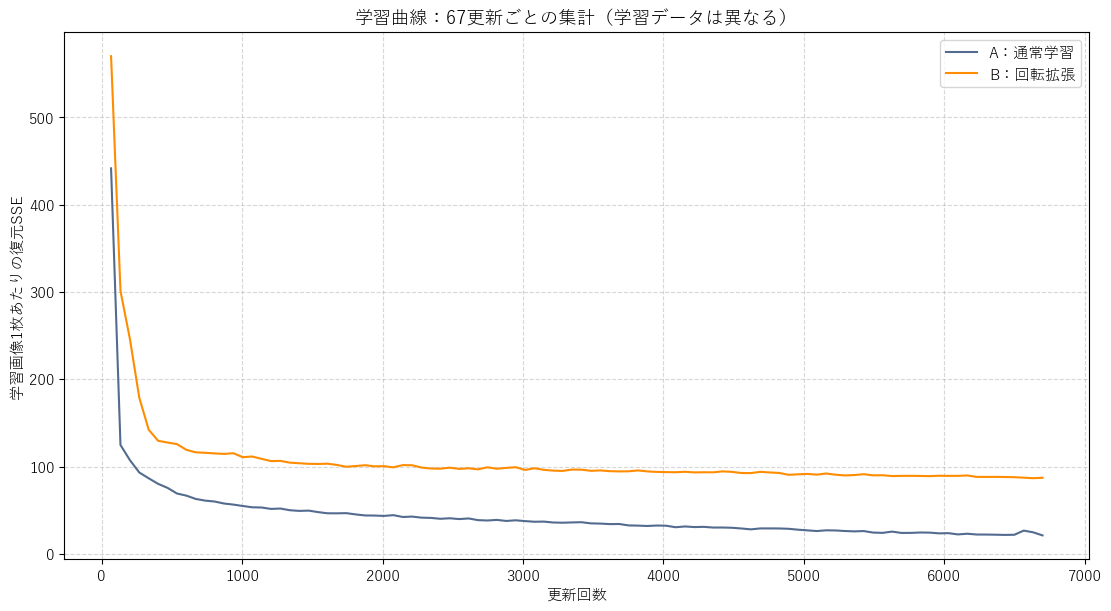

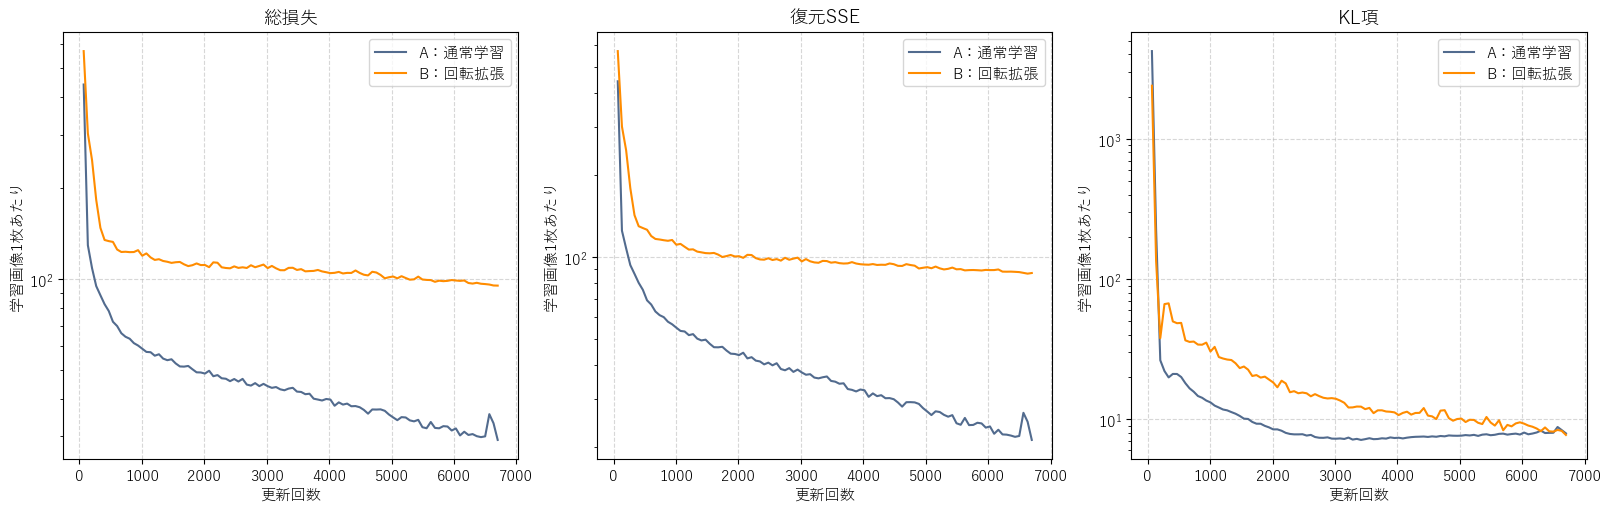

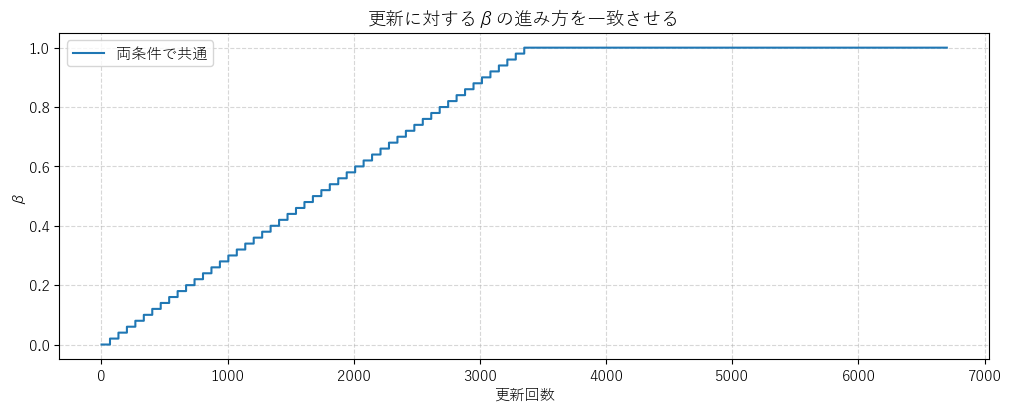

In [9]:
def plot_matched_histories(save_dir):
    histories = {'A_original':normal_history,'B_rotate10':source_history}
    fig,ax = plt.subplots(figsize=(11,6),constrained_layout=True)
    for name,h in histories.items():
        ax.plot(h.cumulative_updates,h.train_sse_per_image,label=LABELS[name],color=COLORS[name])
    ax.set(xlabel='更新回数',ylabel='学習画像1枚あたりの復元SSE',title='学習曲線：67更新ごとの集計（学習データは異なる）')
    ax.grid(ls='--',alpha=.5);ax.legend()
    fig.savefig(save_dir/'train_sse.png',dpi=160);plt.show();plt.close(fig)
    fig,axes = plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
    for ax,column,title in zip(axes,['train_total_per_image','train_sse_per_image','train_kl_per_image'],['総損失','復元SSE','KL項']):
        for name,h in histories.items():
            ax.plot(h.cumulative_updates,np.maximum(h[column],1e-12),label=LABELS[name],color=COLORS[name])
        ax.set(xlabel='更新回数',ylabel='学習画像1枚あたり',title=title,yscale='log')
        ax.grid(ls='--',alpha=.5);ax.legend()
    fig.savefig(save_dir/'training_losses.png',dpi=160);plt.show();plt.close(fig)
    fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
    ax.step(np.arange(1,TARGET_UPDATES+1),beta_by_update,where='post',label='両条件で共通')
    ax.set(xlabel='更新回数',ylabel='β',title='更新に対するβの進み方を一致させる')
    ax.grid(ls='--',alpha=.5);ax.legend()
    fig.savefig(save_dir/'beta_schedule.png',dpi=160);plt.show();plt.close(fig)
plot_matched_histories(RESULT_DIR)


## 7. 共通テスト100枚を平均μから復元してAUROCを比較

SSIM窓11・data_range=1の誤差マップから上位130点を平均します。閾値の探索はしません。


In [10]:
def binary_roc_curve(y_true, scores):
    labels = np.asarray(y_true)
    scores = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or scores.ndim != 1 or labels.shape != scores.shape:
        raise ValueError('ラベルとスコアは同じ長さの1次元配列にしてください。')
    if not np.isfinite(scores).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('スコアは有限値、ラベルは0または1である必要があります。')
    positives = int((labels == 1).sum())
    negatives = int((labels == 0).sum())
    if not positives or not negatives:
        raise ValueError('正常と異常の両方が必要です。')
    order = np.argsort(-scores, kind='stable')
    ordered_scores = scores[order]
    ordered_labels = labels[order]
    ends = np.r_[np.flatnonzero(np.diff(ordered_scores)), len(scores) - 1]
    true_positives = np.cumsum(ordered_labels)[ends]
    false_positives = (ends + 1) - true_positives
    fpr = np.r_[0.0, false_positives / negatives]
    tpr = np.r_[0.0, true_positives / positives]
    thresholds = np.r_[np.inf, ordered_scores[ends]]
    return fpr, tpr, thresholds

def binary_auroc(y_true, scores):
    fpr, tpr, _ = binary_roc_curve(y_true, scores)
    return float(np.trapezoid(tpr, fpr))

assert binary_auroc([0,0,1,1], [0.1,0.2,0.8,0.9]) == 1.0
assert binary_auroc([0,0,1,1], [0.9,0.8,0.2,0.1]) == 0.0
assert binary_auroc([0,0,1,1], [0.5,0.5,0.5,0.5]) == 0.5


def score_model(model_path,images,batch_size=EVAL_BATCH_SIZE):
    model=VAE_Hybrid_CNN_FC(latent_dim=64).to(DEVICE)
    model.load_state_dict(torch.load(model_path,map_location=DEVICE,weights_only=True),strict=True)
    model.eval()
    restored=np.empty((len(images),128,128),dtype=np.float32)
    maps=np.empty_like(restored)
    scores=np.empty(len(images),dtype=np.float64)
    errors=np.empty(len(images),dtype=np.float64)
    with torch.inference_mode():
        for start in range(0,len(images),batch_size):
            x=images[start:start+batch_size].to(DEVICE)
            recon,_,_=model(x,sample=False)
            assert torch.isfinite(recon).all()
            sse=(x-recon).square().flatten(1).sum(1).cpu().numpy()
            for local in range(len(x)):
                index=start+local
                original=x[local,0].cpu().numpy(); output=recon[local,0].cpu().numpy()
                _,smap=ssim(original,output,data_range=1.0,win_size=11,full=True)
                amap=1.0-smap
                assert np.isfinite(amap).all()
                restored[index]=output; maps[index]=amap
                scores[index]=np.mean(np.sort(amap.ravel())[::-1][:TOP_K])
                errors[index]=sse[local]
    del model
    return scores,{'reconstruction':restored,'anomaly_map':maps,'sse_per_image':errors}

def verify_auroc(y,scores):
    value=binary_auroc(y,scores)
    normal=scores[y==0]; abnormal=scores[y==1]
    rank=((abnormal[:,None]>normal).sum()+0.5*(abnormal[:,None]==normal).sum())/(len(normal)*len(abnormal))
    assert np.isclose(value,rank,atol=1e-12)
    return value


In [11]:
all_scores = {}; reconstruction_cache = {}; summary_rows = []
y = image_table.true_label.to_numpy()
for name in CONDITIONS:
    scores,cache = score_model(model_paths[name],input_tensor)
    auc = verify_auroc(y,scores)
    normal_sse = float(cache['sse_per_image'][y==0].mean())
    if name == 'B_rotate10':
        assert np.isclose(normal_sse,source_summary['normal_test_sse_per_image'],rtol=1e-5,atol=1e-4), '保存済み回転拡張の復元結果と一致しません。'
    all_scores[name] = scores
    reconstruction_cache[name] = cache
    summary_rows.append({'condition':name,'seed':SEED,'updates':summaries[name]['updates'],'auroc':auc,
        'normal_test_sse_per_image':normal_sse,'normal_test_mse_per_pixel':normal_sse/(128*128),
        'final_train_sse_per_image':summaries[name]['final_train_sse_per_image'],
        'model_sha256':before_model_hashes[name]})
comparison = pd.DataFrame(summary_rows)
print('以下の学習SSEは各条件の最後の67更新。異なる学習データ上の値です。')


以下の学習SSEは各条件の最後の67更新。異なる学習データ上の値です。


,条件,学習seed,更新回数,AUROC,共通正常画像のSSE/画像,共通正常画像のMSE/画素,最終エポックの学習SSE/画像
0,A：通常学習,42,6700,0.826250,58.5665,0.003575,21.2642
1,B：回転拡張,42,6700,0.806667,78.0388,0.004763,87.2439


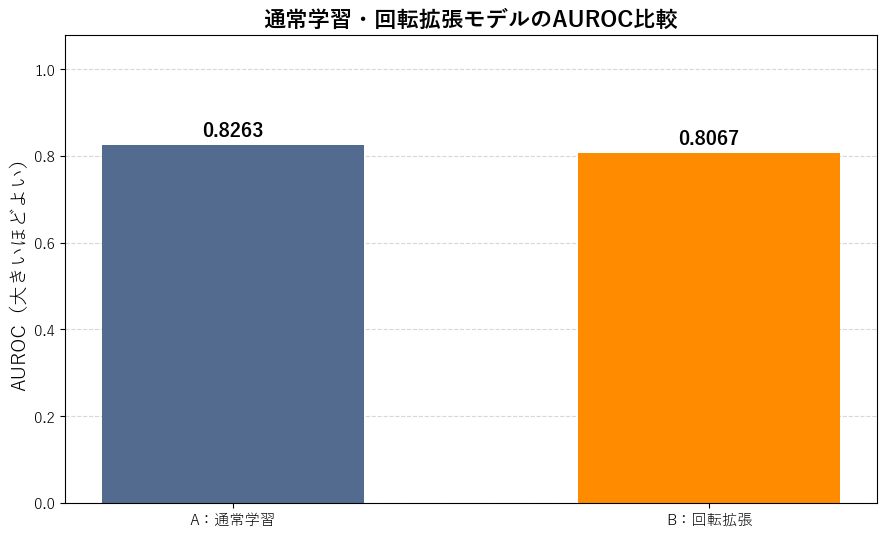

今回の単一シードの比較で最も高いAUROCは **A：通常学習：0.8263** です。学習シードを変えたときのばらつきや、有意な優劣はまだ確認していません。

In [12]:
if READY:
    display(comparison.replace({'condition':LABELS})[['condition','seed','updates','auroc',
                        'normal_test_sse_per_image','normal_test_mse_per_pixel',
                        'final_train_sse_per_image']].rename(columns={
        'condition':'条件','seed':'学習seed','updates':'更新回数','auroc':'AUROC',
        'normal_test_sse_per_image':'共通正常画像のSSE/画像',
        'normal_test_mse_per_pixel':'共通正常画像のMSE/画素',
        'final_train_sse_per_image':'最終エポックの学習SSE/画像',
    }).style.format({'AUROC':'{:.6f}','共通正常画像のSSE/画像':'{:.4f}',
                     '共通正常画像のMSE/画素':'{:.6f}','最終エポックの学習SSE/画像':'{:.4f}'}))

    fig, ax = plt.subplots(figsize=(9,5.5))
    values = comparison.set_index('condition').loc[list(CONDITIONS),'auroc'].to_numpy()
    ax.bar(np.arange(len(CONDITIONS)),values,color=[COLORS[name] for name in CONDITIONS],width=0.55)
    ax.set_xticks(np.arange(len(CONDITIONS)),[LABELS[name] for name in CONDITIONS])
    ax.set_ylim(0,1.08)
    ax.set_yticks(np.linspace(0,1,6))
    ax.set_ylabel('AUROC（大きいほどよい）',fontsize=14)
    ax.set_title('通常学習・回転拡張モデルのAUROC比較',fontsize=16,fontweight='bold')
    for i,value in enumerate(values):
        ax.text(i,value+0.02,f'{value:.4f}',ha='center',fontsize=14,fontweight='bold')
    ax.grid(axis='y',linestyle='--',alpha=0.5)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(RESULT_DIR/'auroc_comparison.png',dpi=150)
    plt.show()
    plt.close(fig)

    winner = comparison.loc[comparison.auroc.idxmax()]
    display(Markdown(f'今回の単一シードの比較で最も高いAUROCは **{LABELS[winner.condition]}：{winner.auroc:.4f}** です。'
                     '学習シードを変えたときのばらつきや、有意な優劣はまだ確認していません。'))
else:
    print('正式結果待ち：この比較表示はまだありません。')


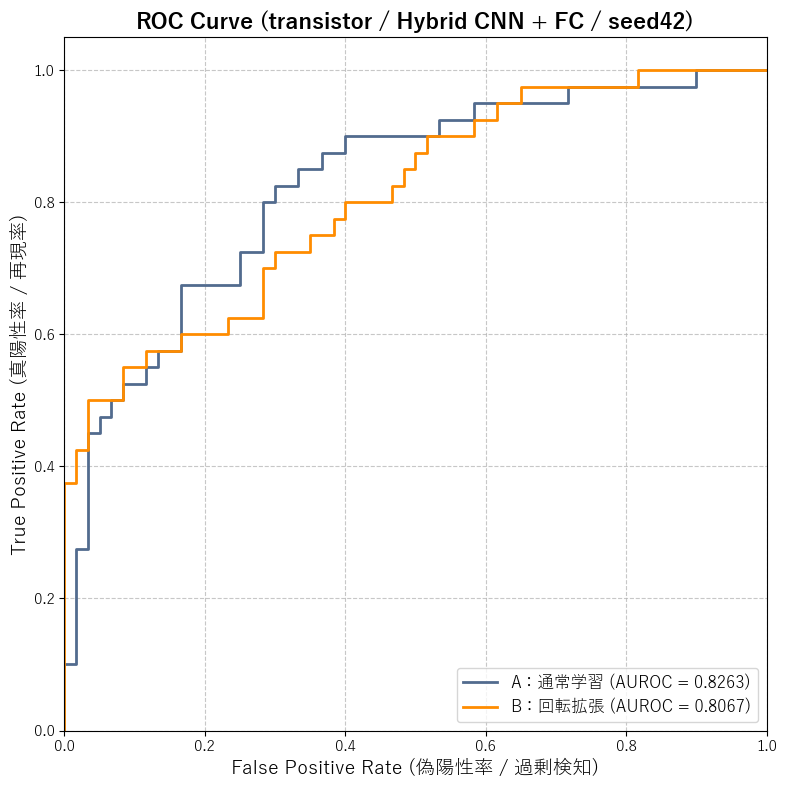

In [13]:
if READY:
    fig, ax = plt.subplots(figsize=(8,8))
    for name in CONDITIONS:
        fpr,tpr,_ = binary_roc_curve(image_table.true_label.to_numpy(),all_scores[name])
        auc_value = float(comparison.loc[comparison.condition==name,'auroc'].iloc[0])
        ax.plot(fpr,tpr,color=COLORS[name],lw=2,label=f'{LABELS[name]} (AUROC = {auc_value:.4f})')
    ax.set_xlim([0.0,1.0])
    ax.set_ylim([0.0,1.05])
    ax.set_xlabel('False Positive Rate (偽陽性率 / 過剰検知)',fontsize=14)
    ax.set_ylabel('True Positive Rate (真陽性率 / 再現率)',fontsize=14)
    ax.set_title(f'ROC Curve (transistor / Hybrid CNN + FC / seed{SEED})',fontsize=16,fontweight='bold')
    ax.legend(loc='lower right',fontsize=12)
    ax.grid(True,linestyle='--',alpha=0.7)
    fig.tight_layout()
    fig.savefig(RESULT_DIR/'roc_comparison.png',dpi=150)
    plt.show()
    plt.close(fig)
else:
    print('正式結果待ち：この比較表示はまだありません。')


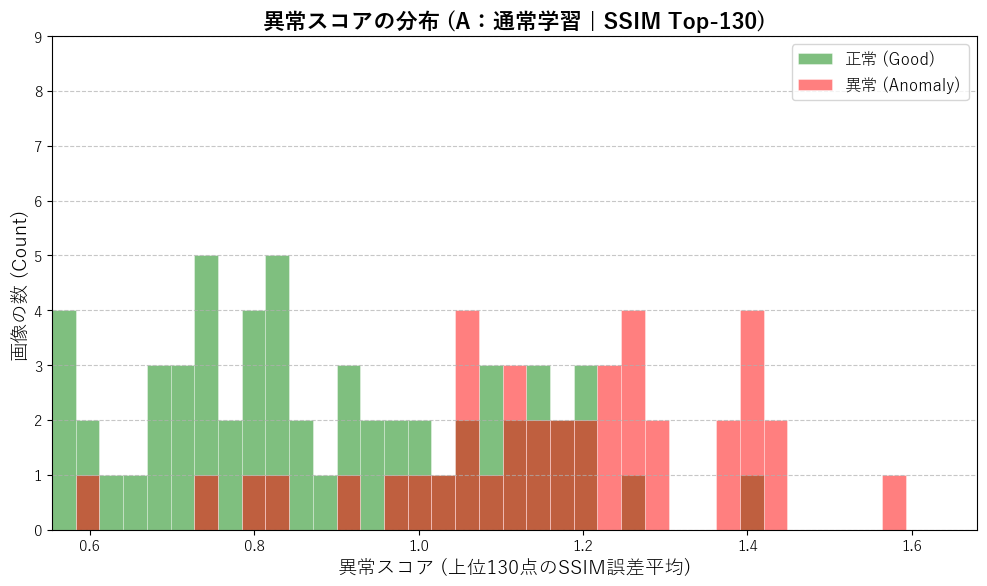

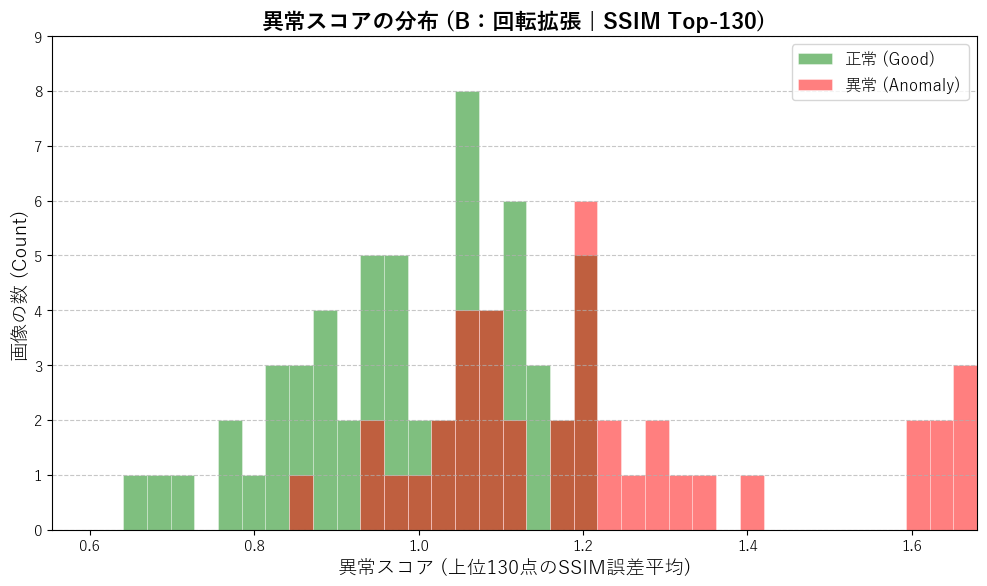

In [14]:
if READY:
    joined_scores = np.concatenate([all_scores[name] for name in CONDITIONS])
    lo,hi=float(joined_scores.min()),float(joined_scores.max())
    if hi<=lo: lo-=1e-6;hi+=1e-6
    common_bins = np.linspace(lo,hi,40)
    y = image_table.true_label.to_numpy()
    max_count = max(np.histogram(all_scores[name][y==label],bins=common_bins)[0].max()
                    for name in CONDITIONS for label in [0,1])
    for name in CONDITIONS:
        fig,ax = plt.subplots(figsize=(10,6))
        ax.hist(all_scores[name][y==0],bins=common_bins,color='green',alpha=0.5,
                edgecolor='white',linewidth=0.5,label='正常 (Good)')
        ax.hist(all_scores[name][y==1],bins=common_bins,color='red',alpha=0.5,
                edgecolor='white',linewidth=0.5,label='異常 (Anomaly)')
        ax.set_xlim(common_bins[0],common_bins[-1])
        ax.set_ylim(0,max_count+1)
        ax.set_title(f'異常スコアの分布 ({LABELS[name]} | SSIM Top-{TOP_K})',fontsize=16,fontweight='bold')
        ax.set_xlabel(f'異常スコア (上位{TOP_K}点のSSIM誤差平均)',fontsize=14)
        ax.set_ylabel('画像の数 (Count)',fontsize=14)
        ax.legend(fontsize=12)
        ax.grid(axis='y',linestyle='--',alpha=0.7)
        fig.tight_layout()
        fig.savefig(RESULT_DIR/f'score_distribution_{name}.png',dpi=150)
        plt.show()
        plt.close(fig)
else:
    print('正式結果待ち：この比較表示はまだありません。')


## 8. 異常種類別AUROC（各異常10枚と正常60枚）

少数画像・単一シードの補足評価です。結果の安定性や統計的な優位性を示すものではありません。


condition,A：通常学習,B：回転拡張
category_ja,,
本体の損傷,0.758333,0.710000
端子の切断,0.761667,0.700000
端子の曲がり,0.800000,0.851667
配置ずれ,0.985000,0.965000


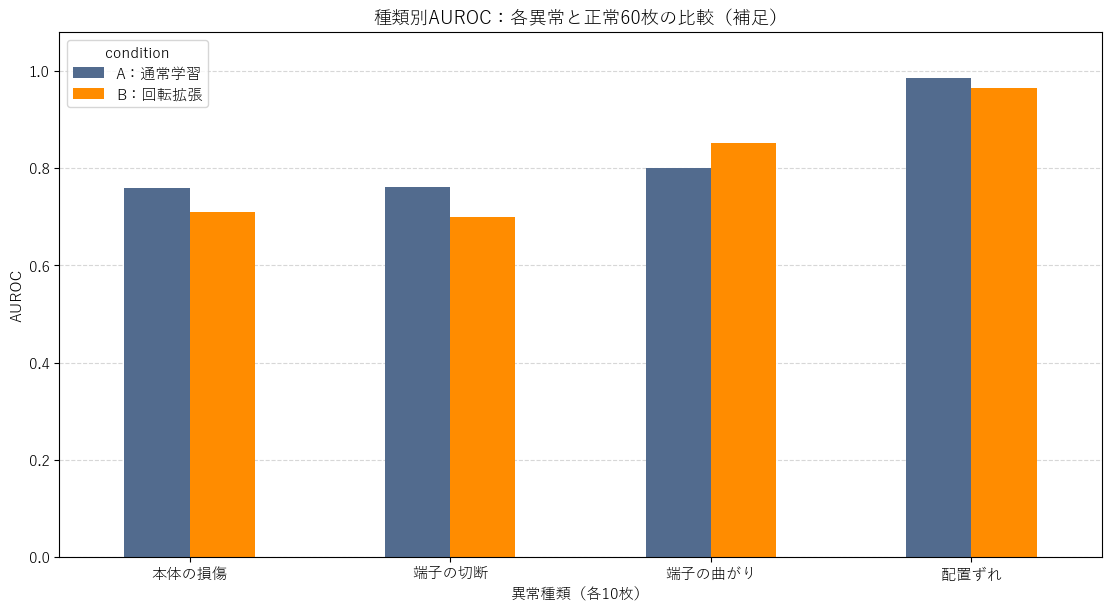

In [15]:
category_auroc=pd.DataFrame()
if READY:
    rows=[]
    for category in category_labels:
        if category=='good':continue
        selected=image_table.category.isin(['good',category]).to_numpy()
        for name in CONDITIONS:
            rows.append({'condition':name,'category':category,'category_ja':category_labels[category],
                         'normal_count':60,'anomaly_count':10,
                         'auroc':verify_auroc(image_table.true_label.to_numpy()[selected],all_scores[name][selected])})
    category_auroc=pd.DataFrame(rows)
    display(category_auroc.pivot(index='category_ja',columns='condition',values='auroc').rename(columns=LABELS))
    fig,ax=plt.subplots(figsize=(11,6),constrained_layout=True)
    table=category_auroc.pivot(index='category_ja',columns='condition',values='auroc').loc[:,list(CONDITIONS)]
    table.rename(columns=LABELS).plot.bar(ax=ax,color=[COLORS[n] for n in CONDITIONS],rot=0)
    ax.set(ylim=(0,1.08),xlabel='異常種類（各10枚）',ylabel='AUROC',title='種類別AUROC：各異常と正常60枚の比較（補足）')
    ax.grid(axis='y',ls='--',alpha=.5);ax.set_axisbelow(True)
    fig.savefig(RESULT_DIR/'category_auroc.png',dpi=160);plt.show();plt.close(fig)
else:print('正式結果待ちです。')


## 9. 入力・復元・SSIM誤差マップ

評価で実際に使った復元を表示します。色範囲は全画像・両モデル共通0〜2。誤差マップは欠陥位置の正解ラベルではありません。MAX_IMAGES_PER_CATEGORY=Noneで全100枚に切り替えられます。


正常（good）：1枚 / 全60枚


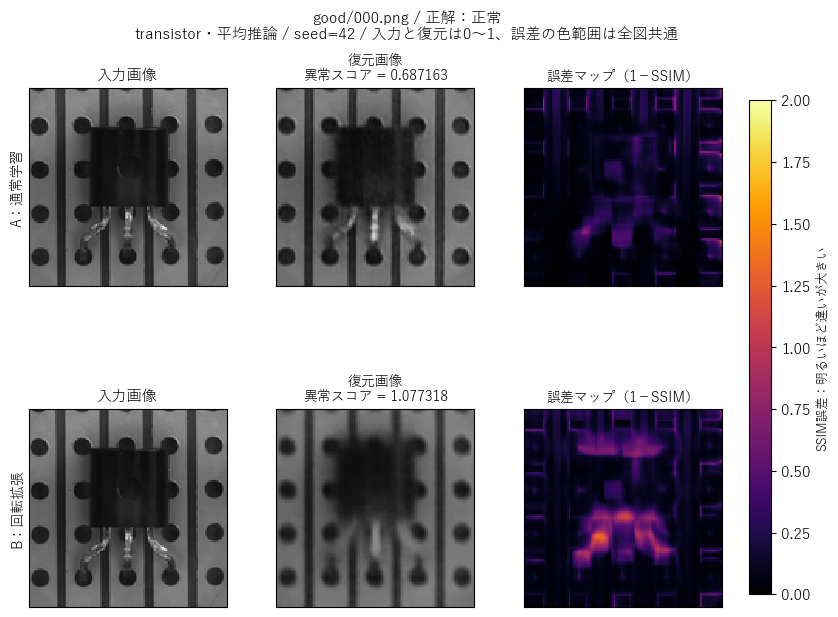

端子の曲がり（bent_lead）：1枚 / 全10枚


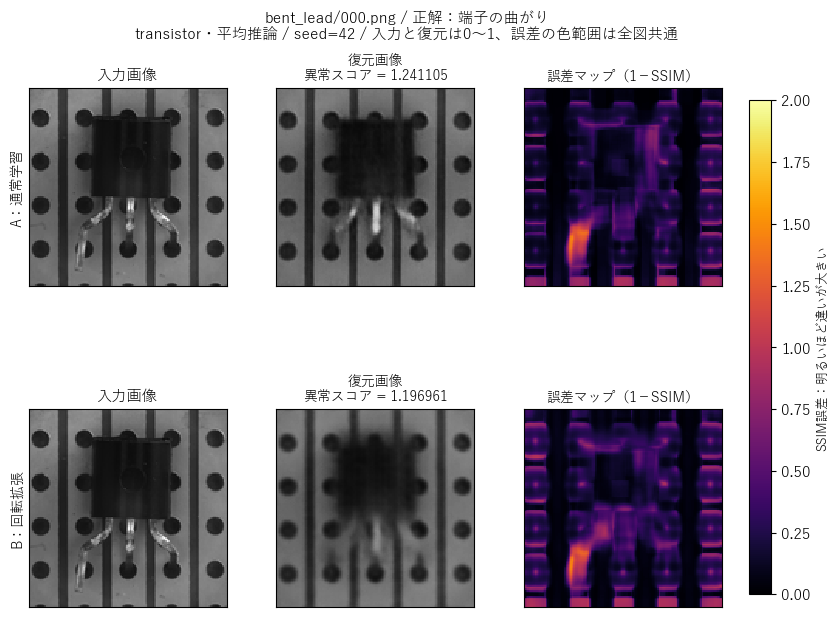

端子の切断（cut_lead）：1枚 / 全10枚


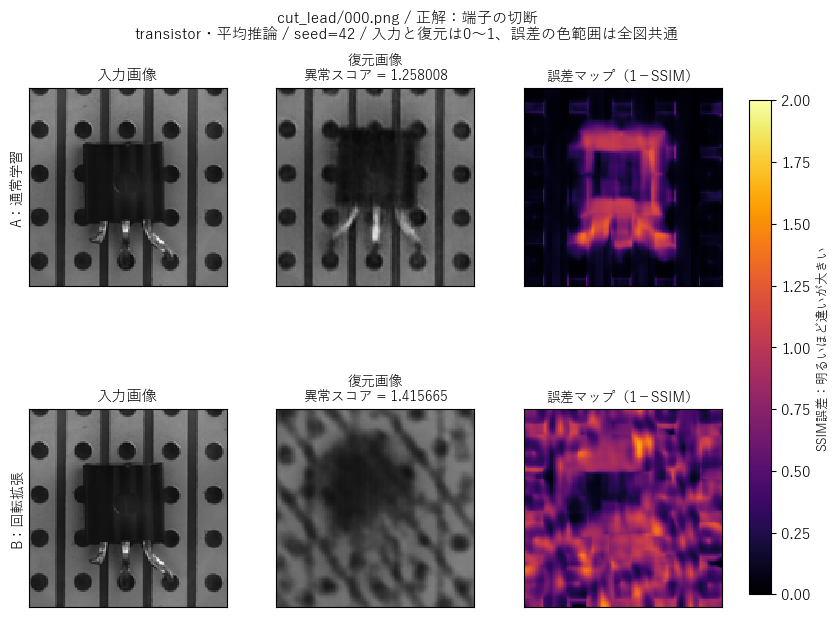

本体の損傷（damaged_case）：1枚 / 全10枚


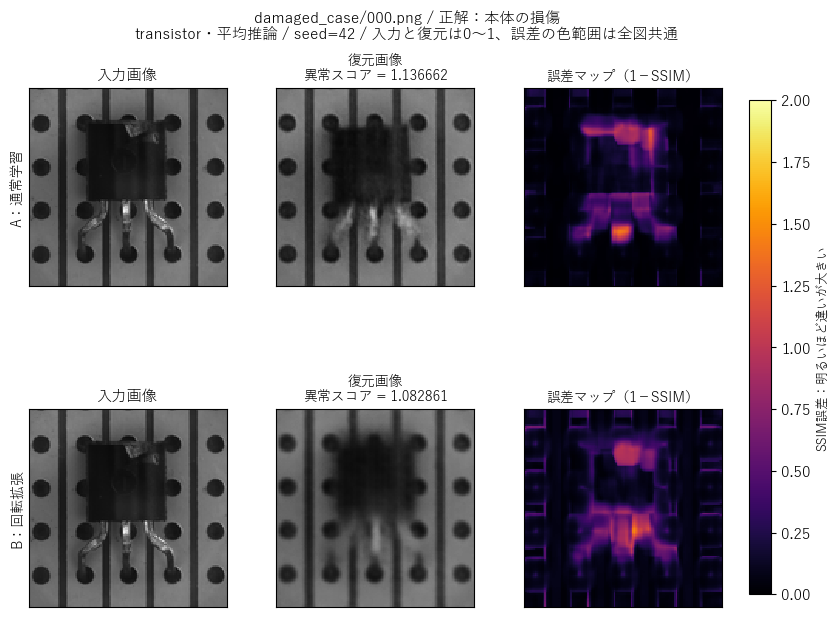

配置ずれ（misplaced）：1枚 / 全10枚


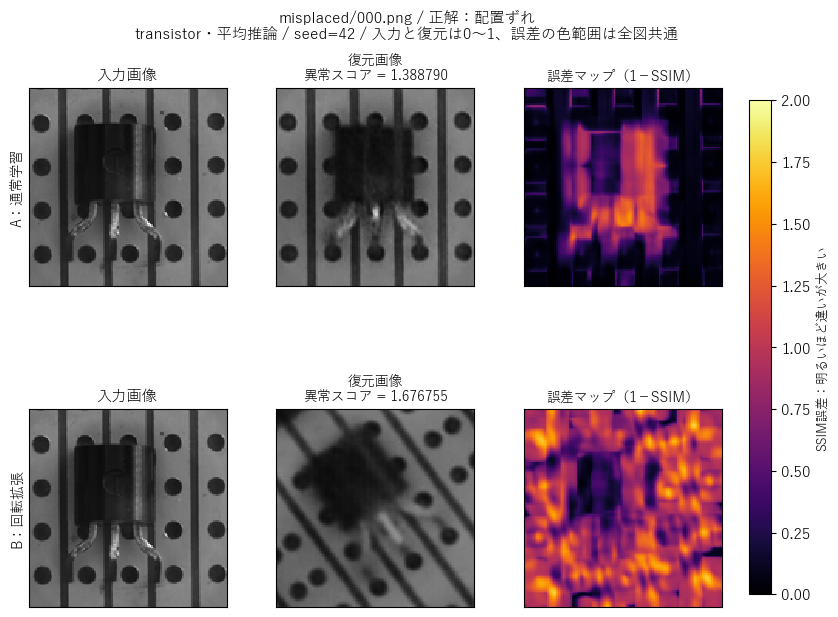

In [16]:
VISUALIZE_CATEGORIES=None  # 例：['good','misplaced']
VISUALIZE_PATHS=None  # 例：['good/000.png']
VISUAL_MAP_VMIN=0.0;VISUAL_MAP_VMAX=2.0
def show_category_reconstructions(category):
    if VISUALIZE_CATEGORIES is not None and category not in VISUALIZE_CATEGORIES:
        print(f'{category_labels[category]}：設定により表示しません。')
        return 0
    selected = image_table.index[image_table.category == category].tolist()
    if VISUALIZE_PATHS is not None:
        selected = [index for index in selected if image_table.loc[index, 'relative_path'] in VISUALIZE_PATHS]
    if MAX_IMAGES_PER_CATEGORY is not None:
        selected = selected[:MAX_IMAGES_PER_CATEGORY]
    print(f'{category_labels[category]}（{category}）：{len(selected)}枚 / 全{counts[category]}枚')
    for index in selected:
        record = image_table.loc[index]
        original = input_tensor[index, 0].cpu().numpy()
        fig, axes = plt.subplots(len(CONDITIONS), 3, figsize=(9, 6.5), dpi=100)
        fig.subplots_adjust(left=0.08, right=0.85, bottom=0.03, top=0.89, wspace=0.25, hspace=0.35)
        for row, name in enumerate(CONDITIONS):
            output = reconstruction_cache[name]['reconstruction'][index]
            error_map = reconstruction_cache[name]['anomaly_map'][index]
            axes[row, 0].imshow(original, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            axes[row, 1].imshow(output, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            heat = axes[row, 2].imshow(error_map, cmap='inferno', vmin=VISUAL_MAP_VMIN,
                                      vmax=VISUAL_MAP_VMAX, interpolation='nearest')
            axes[row, 0].set_title('入力画像', fontsize=11)
            axes[row, 0].set_ylabel(LABELS[name], fontsize=10)
            axes[row, 1].set_title(f'復元画像\n異常スコア = {all_scores[name][index]:.6f}', fontsize=10)
            axes[row, 2].set_title('誤差マップ（1−SSIM）', fontsize=10)
            for ax in axes[row]:
                ax.set_xticks([]); ax.set_yticks([])
        colorbar_axis = fig.add_axes([0.88, 0.08, 0.025, 0.76])
        bar = fig.colorbar(heat, cax=colorbar_axis)
        bar.set_label('SSIM誤差：明るいほど違いが大きい', fontsize=9)
        fig.suptitle(f'{record.relative_path} / 正解：{record.category_ja}\n'
                     f'transistor・平均推論 / seed={SEED} / 入力と復元は0〜1、誤差の色範囲は全図共通', fontsize=11)
        fig.canvas.draw()
        plt.show()
        plt.close(fig)
    if not selected:
        print('表示条件に該当する画像はありません。')
    return len(selected)

if READY:
    if MAX_IMAGES_PER_CATEGORY is not None:
        assert isinstance(MAX_IMAGES_PER_CATEGORY,int) and not isinstance(MAX_IMAGES_PER_CATEGORY,bool) and MAX_IMAGES_PER_CATEGORY>0
    for name in CONDITIONS:
        expected=np.sort(reconstruction_cache[name]['anomaly_map'].reshape(len(image_table),-1),axis=1)[:,-TOP_K:].mean(1)
        assert np.allclose(expected,all_scores[name],atol=1e-7)
    for category in category_labels:show_category_reconstructions(category)
else:print('正式モデルの評価後に表示します。')


## 10. 結果と再現情報を新規評価フォルダへ保存

保存済み回転拡張モデル・設定・ログのハッシュが変わっていないことも確認します。


In [17]:
score_table = image_table[['relative_path','category_ja','true_label']].copy()
for name in CONDITIONS:
    score_table[name] = all_scores[name]
comparison.to_csv(RESULT_DIR/'comparison.csv',index=False)
category_auroc.to_csv(RESULT_DIR/'category_auroc.csv',index=False)
score_table.to_csv(RESULT_DIR/'image_scores.csv',index=False)
normal_rows = []
for name in CONDITIONS:
    for index in image_table.index[image_table.true_label == 0]:
        value = float(reconstruction_cache[name]['sse_per_image'][index])
        normal_rows.append({'condition':name,'relative_path':image_table.loc[index,'relative_path'],
                            'sse_per_image':value,'mse_per_pixel':value/(128*128)})
pd.DataFrame(normal_rows).to_csv(RESULT_DIR/'normal_test_errors.csv',index=False)
np.savez_compressed(RESULT_DIR/'reconstruction_cache.npz',
    input=input_tensor.numpy(),relative_paths=image_table.relative_path.to_numpy(dtype=str),
    **{f'{name}_{key}':value for name,cache in reconstruction_cache.items() for key,value in cache.items()})
record = {'evaluation_datetime_jst':datetime.now(ZoneInfo('Asia/Tokyo')).isoformat(),
          'normal_run_id':RUN_ID,'rotation_source_run':SOURCE_RUN.relative_to(ROOT).as_posix(),
          'model_hashes':before_model_hashes,'seed':SEED,'target_updates':TARGET_UPDATES,
          'beta_schedule_sha256':beta_sha256,'test_manifest_sha256':manifest_hash,
          'inference':'posterior mean; eval mode; no sampling','ssim_window':11,'top_k':TOP_K,
          'preprocessing':source_config['test_preprocessing'],'metrics':comparison.to_dict('records'),
          'normal_training_config':train_config,'rotation_training_config':source_config,
          'limitations':['single seed','different input distributions and sample orders',
                        'different batch-size sequences and total sample counts',
                        'training errors are not evaluated on common data'],
          'python':platform.python_version(), 'device':str(DEVICE),'torch_threads':torch.get_num_threads(),
          'versions':{v:importlib.metadata.version(v) for v in ['torch','torchvision','numpy','scikit-image','Pillow']}}
write_json(RESULT_DIR/'evaluation_record.json',record)
assert all(sha256(model_paths[n]) == before_model_hashes[n] for n in CONDITIONS)
assert all(sha256(ROOT/p) == value for p,value in source_file_hashes.items()), '読み込み元が実行中に変化しました。'
print('結果保存先：',RESULT_DIR)
print('再学習を省く場合はRUN_FULL_TRAINING=False、NORMAL_RUN_ID=',repr(RUN_ID))


結果保存先： c:\Users\tokiy\my_GitHub\image-anomaly-detection\saved_models\transistor_update_matched_20261106\20261106_021112_b266ecab\evaluations\20261106_025126_58aad9c8
再学習を省く場合はRUN_FULL_TRAINING=False、NORMAL_RUN_ID= '20261106_021112_b266ecab'


## 結果の読み取りと参照先

- 更新回数だけでなく、βの進み方を揃えた比較です。元の通常学習100エポック（700更新）とは別の実験として扱います。
- 通常学習の更新を増やすと改善するか、回転拡張との差が残るかは実行結果から判断します。性能向上は事前に仮定しません。
- 学習の復元損失・共通正常画像の復元品質・異常検知AUROCを区別します。正常をよく復元しても異常検知が良くなるとは限りません。
- 本比較ではHybrid CNN＋FCを維持します。CNN Deep5への変更を混ぜません。
- 既存のテスト結果を既に確認して設計した追試であり、独立した最終評価を示すものではありません。

参照：[既存の比較学習・評価ノートブック](../261105transistorの通常学習とreflect回転拡張の比較学習とAUROC評価.ipynb)、[反復拡張とエポック数の違い](../../../docs/experiments/反復拡張とエポック数の違い.md)。詳細な回転処理は読み込み元のconfigに記録されています。

このノートブックはコード作成・静的確認のみで保存しています。出力・学習結果・図の表示はユーザー実行後に確認してください。
